In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei'] #用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号

In [3]:
path = 'data/regress_data1.csv' #数据集路径
data = pd.read_csv(path) #读取数据
data.head() #查看数据的前五行
data.describe()   #查看数据的统计信息

,人口,收益
count,97.000000,97.000000
mean,8.159800,5.839135
std,3.869884,5.510262
min,5.026900,-2.680700
25%,5.707700,1.986900
50%,6.589400,4.562300
75%,8.578100,7.046700
max,22.203000,24.147000


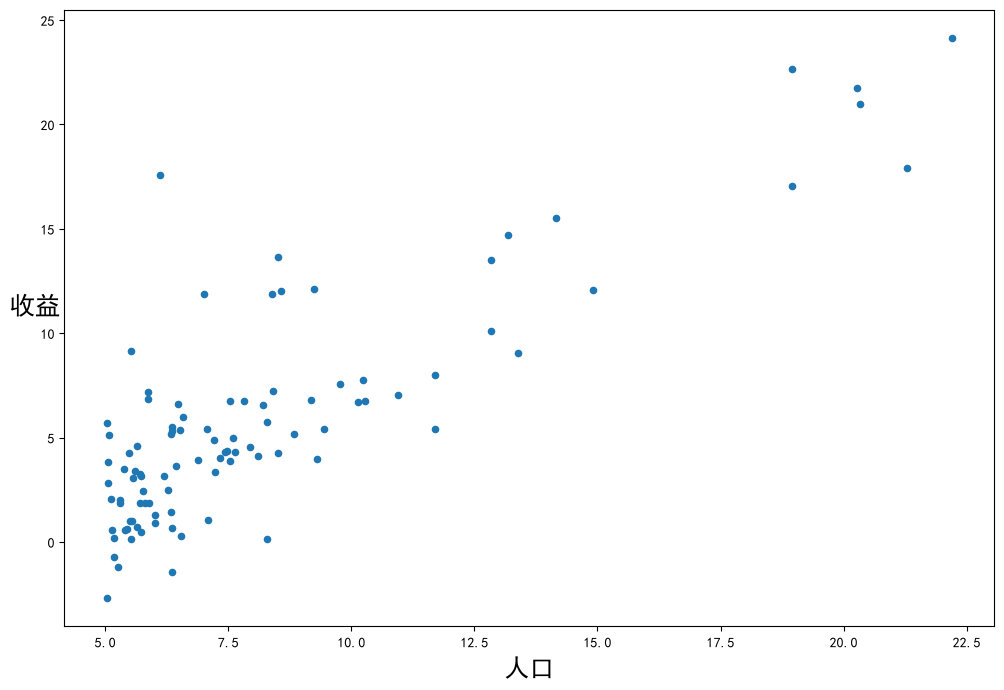

In [4]:
# 绘制散点图
data.plot(kind='scatter', x='人口', y='收益', figsize=(12,8))
# 设置x轴标签
plt.xlabel('人口', fontsize=18)
# 设置y轴标签，并将标签旋转为水平方向
plt.ylabel('收益', rotation=0, fontsize=18)
# 显示图形
plt.show()

In [5]:
def computeCost(X, y, w):
    """
    计算线性回归模型的代价函数。    
    参数：
    X -- 特征矩阵，形状为 (n_samples, n_features)
    y -- 标签向量，形状为 (n_samples,1)
    w -- 权重向量，形状为 (n_features,1)
    返回值：
    代价函数的值
    """
    inner = np.power(X @ w - y, 2)  # 计算预测值与实际值之差的平方和
    return np.sum(inner) / (2 * len(X))  # 对平方和进行求和并除以样本数量的两倍，得到代价函数的值

In [6]:
#让我们在训练集中添加一列，以便我们可以使用向量化的解决方案来计算代价和梯度。将一列名为'Ones'的值全为1的列插入到data的第一列位置。
data.insert(0, 'Ones', 1)
#变量初始化
cols = data.shape[1]  # 获取data的列数
X = data.iloc[:,:cols-1]  # 获取除最后一列外的所有列作为特征矩阵X
y = data.iloc[:,cols-1:]  # 获取最后一列作为目标变量y
X.head()#head()是观察前5行
y.head()#head()是观察前5行


,收益
0,17.5920
1,9.1302
2,13.6620
3,11.8540
4,6.8233


In [7]:
X = X.values
y = y.values
w = np.zeros((X.shape[1], 1)) #代价函数是应该是numpy矩阵，所以我们需要转换X和Y，然后才能使用它们。 我们还需要初始化w。
computeCost(X, y, w) # 计算初始代价函数值

np.float64(32.072733877455676)

In [ ]:
def batch_gradientDescent(X, y, w, alpha, count):
    """
    批量梯度下降算法实现。
    参数：
    X -- 特征矩阵，形状为 (n_samples, n_features)
    y -- 标签向量，形状为 (n_samples,1)
    w -- 权重向量，形状为 (n_features,1)
    alpha -- 学习率
    count -- 迭代次数
    返回值：
    w -- 更新后的权重向量
    costs -- 每次迭代的代价函数值列表
    """
    # 初始化代价函数值列表
    costs = []

    # 对每个样本进行迭代
    for i in range(count):
        # 根据公式更新权重向量
        w = w - (X.T @ (X @ w - y)) * alpha / len(X)

        # 计算当前代价函数值并添加到列表中
        cost = computeCost(X, y, w)
        costs.append(cost)

        # 每隔100次迭代输出一次当前代价函数值
        if i % 100 == 0:
            print("在第{}次迭代中，cost的值是：{}。".format(i, cost))

    # 返回最终的权重向量和代价函数值列表
    return w, costs